# Week 4 segmentation, step by step

One query image goes through `segmentation.detect_paintings`:

| Step | What | From |
|---|---|---|
| 0 | Denoising (`denoising.denoise_image`) | W3 / W4 |
| 1 | Resize to `WORK_SIDE` | |
| 2 | Gradient of HSV S,V and edges (k · Otsu) | W3 |
| 3 | Closing, hole filling, opening → regions | W3 |
| 4 | Wall colour model: Mahalanobis distance of Lab a,b to the border | W2 |
| 5 | Split regions where there is only wall (no colour, no edges) | **new** |
| 6 | Selection by area and rectangularity | W3 |
| 7 | Projection rectangle | W2 |
| 8 | Fallback to the whole image when nothing is found | **new** |

Change `IDX` to follow another image. Good examples: **20** and **28** (stacked paintings that Week 3 merged),
**6** (stacked, with a shadow between them), **17** (the painting fills the image), **2** (two paintings side by side).

Up to 3 paintings are detected. No query set has 3, so `searches/segmentation_3paintings_test.py` builds
`data/synthetic_w4` (real walls + museum paintings). Set `QUERY_DIR = DATA / "synthetic_w4"` to follow one of them,
e.g. **48** (3 stacked, shifted sideways), **60** (2 stacked next to 1), **75** (1 above 2), **30** (3 in a row).

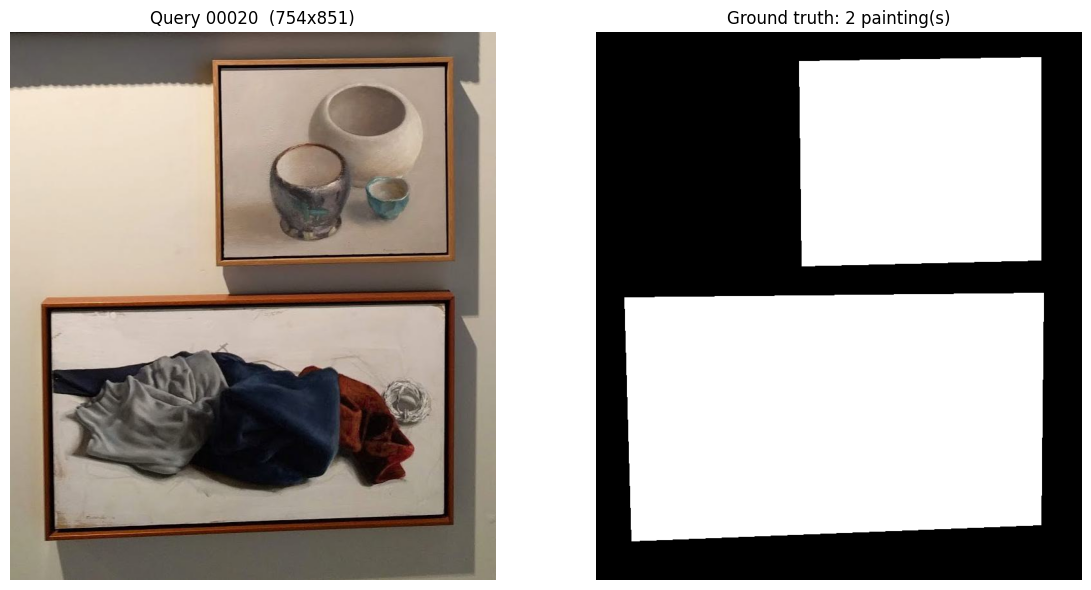

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path.cwd().parent))  # w4/

import segmentation as S
from denoising import denoise_image, impulse_fraction
from utils import overlay_masks

# Week 3 detection, for the comparison at the end (it lives in w3/utils.py)
import importlib.util
_spec = importlib.util.spec_from_file_location("w3_utils", Path.cwd().parent.parent / "w3" / "utils.py")
w3_utils = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(w3_utils)
detect_paintings_w3 = w3_utils.detect_paintings

DATA = Path.cwd().parent.parent / "data"
IDX = 20
QUERY_DIR = DATA / "qsd1_w4"   # or DATA / "synthetic_w4" (3-painting images, see above)


def show(images, titles, size=4.5, cmap="gray"):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img, cmap=cmap)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def scores(masks, gt):
    pred = np.zeros(gt.shape, bool)
    for m in masks:
        pred |= m > 0
    tp, fp, fn = (pred & gt).sum(), (pred & ~gt).sum(), (~pred & gt).sum()
    p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return p, r, 2 * p * r / max(p + r, 1e-9)


img = cv2.imread(str(QUERY_DIR / f"{IDX:05d}.jpg"))
gt = cv2.imread(str(QUERY_DIR / f"{IDX:05d}.png"), cv2.IMREAD_GRAYSCALE) > 0
n_gt = cv2.connectedComponents(gt.astype(np.uint8))[0] - 1
show([img, gt.astype(np.uint8)], [f"Query {IDX:05d}  ({img.shape[1]}x{img.shape[0]})", f"Ground truth: {n_gt} painting(s)"], size=6)

## 0. Denoising

Segmentation runs on the denoised image, as in `main.py`. Images with impulse noise (> 1% isolated pixels)
are filtered; the rest are unchanged.

In [2]:
frac = impulse_fraction(img)
den = denoise_image(img)
print(f"Isolated pixels: {frac:.2%} -> {'noisy, filtered' if frac > 0.01 else 'clean, unchanged'}")

steps = S.segment_steps(den)   # every intermediate result of detect_paintings
work = steps["work"]
print(f"Work size: {work.shape[1]}x{work.shape[0]} (longest side <= {S.WORK_SIDE})")

Isolated pixels: 0.00% -> clean, unchanged


Work size: 754x851 (longest side <= 1024)


## 1-2. Gradient and edges (Week 3)

Prewitt gradient of the HSV **S** and **V** channels (the maximum of both, each normalised), then a threshold
of `EDGE_K` × Otsu. A plain Otsu threshold would keep only the strongest painting's edges, so a lower
threshold is used. The image border is cleared because it is wall.

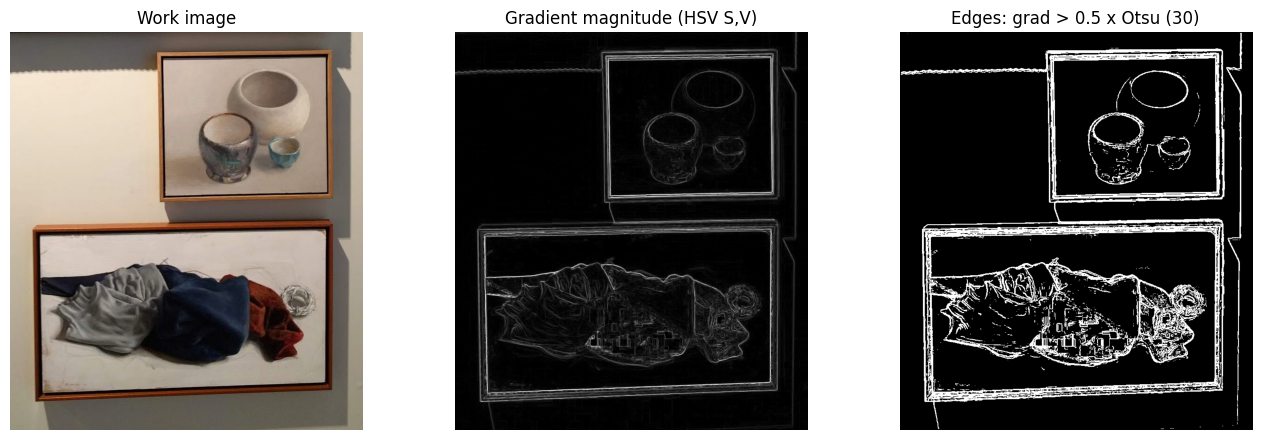

In [3]:
otsu, _ = cv2.threshold(steps["grad"], 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
show([work, steps["grad"], steps["edges"]],
     ["Work image", "Gradient magnitude (HSV S,V)", f"Edges: grad > {S.EDGE_K} x Otsu ({S.EDGE_K * otsu:.0f})"])

## 3. Regions (Week 3)

**Closing** joins the gaps of each frame outline, **hole filling** turns closed outlines into solid
paintings, and **opening** removes thin structures (wires, labels) before filling again.

When two paintings are close, the closing and the hole filling can also fill the strip of wall between
them, and they become **one region**. That is what step 5 fixes.

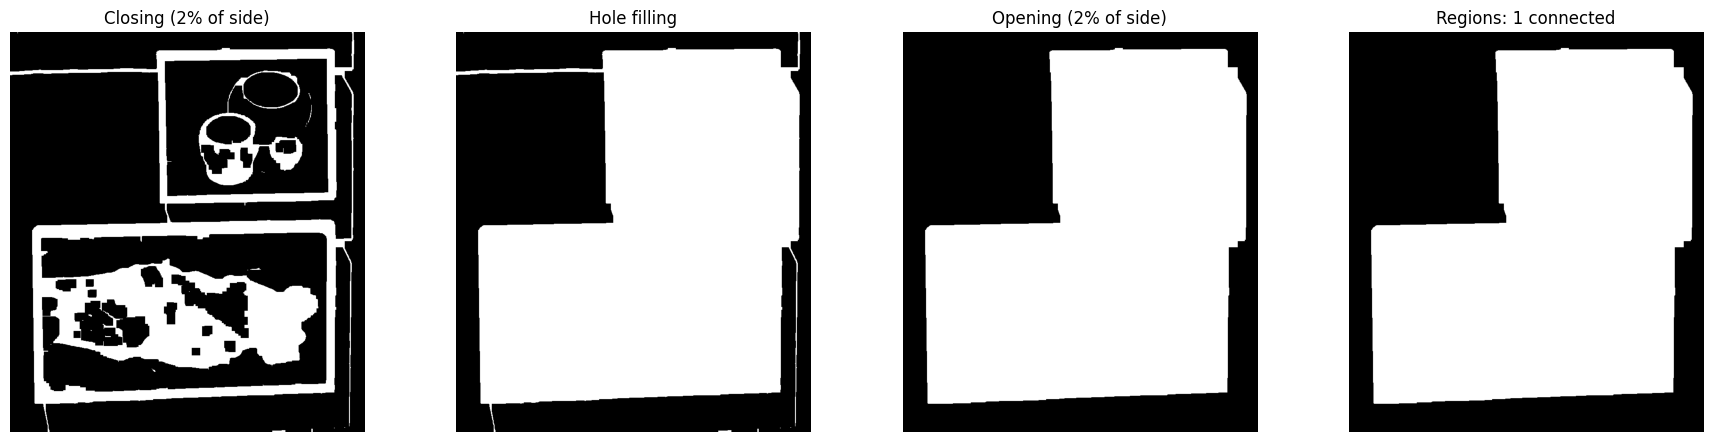

In [4]:
closed = cv2.morphologyEx(steps["edges"], cv2.MORPH_CLOSE, S.square_kernel(S.CLOSE_FRAC, work.shape[:2]))
filled = S.fill_holes(closed)
opened = cv2.morphologyEx(filled, cv2.MORPH_OPEN, S.square_kernel(S.OPEN_FRAC, work.shape[:2]))
n_regions = cv2.connectedComponents(steps["regions"])[0] - 1
show([closed, filled, opened, steps["regions"]],
     [f"Closing ({S.CLOSE_FRAC:.0%} of side)", "Hole filling", f"Opening ({S.OPEN_FRAC:.0%} of side)",
      f"Regions: {n_regions} connected"])

## 4. Wall colour model (Week 2)

The border of the image is wall. A Gaussian is fitted to the **Lab a,b** colour of the border pixels (the
20% farthest from the median are dropped, in case a painting touches the border) and every pixel gets its
Mahalanobis distance to it. Only chroma is used, so shadows (which only change L) count as wall.

The **content** map marks the evidence of a painting: pixels that are **not wall-coloured** or that are **on an edge**.
Inside a painting there is always content; the strip of wall between two paintings has none.

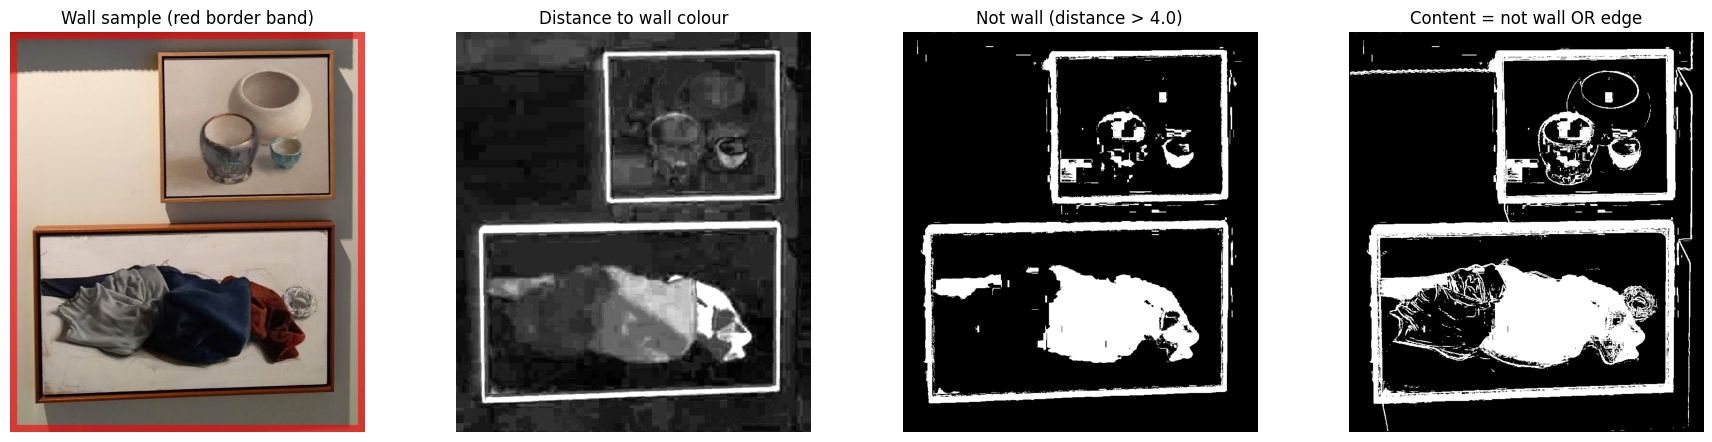

In [5]:
h, w = work.shape[:2]
sample = work.copy()
band = S.border_mask(h, w, max(2, int(S.WALL_BORDER_FRAC * min(h, w))))
sample[band] = (0.4 * sample[band] + 0.6 * np.array([0, 0, 255])).astype(np.uint8)
show([sample, np.clip(steps["wall_dist"], 0, 3 * S.WALL_THR), (steps["wall_dist"] > S.WALL_THR).astype(np.uint8),
      steps["content"]],
     ["Wall sample (red border band)", "Distance to wall colour", f"Not wall (distance > {S.WALL_THR})",
      "Content = not wall OR edge"])

## 5. Split merged paintings (new in Week 4)

For every region, the fraction of content pixels is measured per **row** and per **column** inside its
bounding box. The region is cut at the minimum of a profile when it is below `SPLIT_THR` × the median content
of both sides. The minimum is only searched where both parts would be at least 15% of the region and not more
elongated than `SPLIT_MAX_ASPECT` (8:1), so the plain band of a frame is never cut off as a painting (grey areas
in the plots). The cut is applied recursively, so a region can be split more than once (3 paintings in a row).

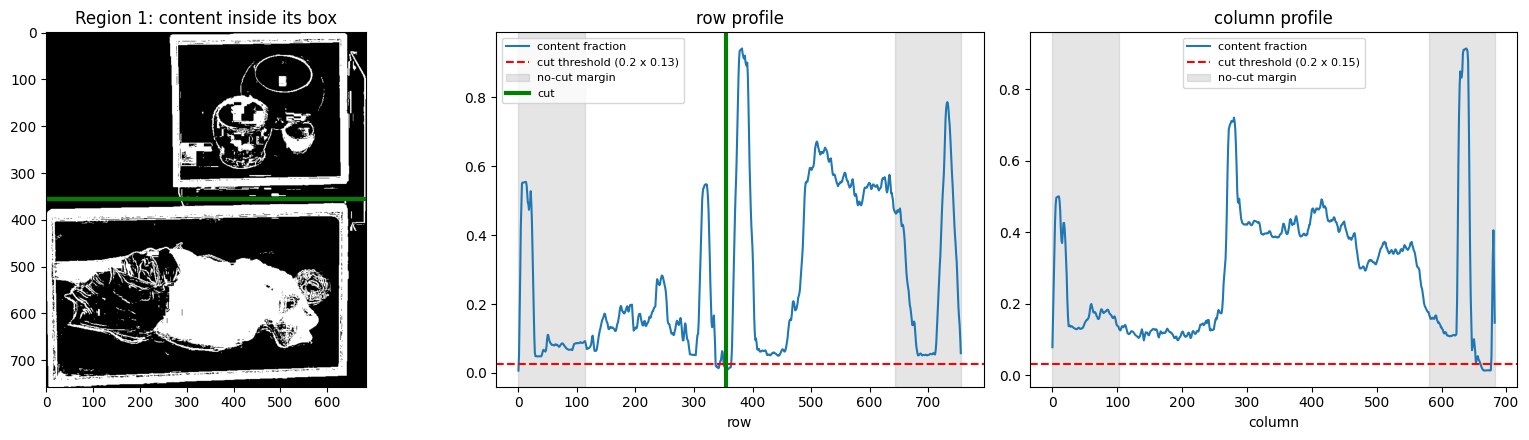

Region 1: cut at row 389


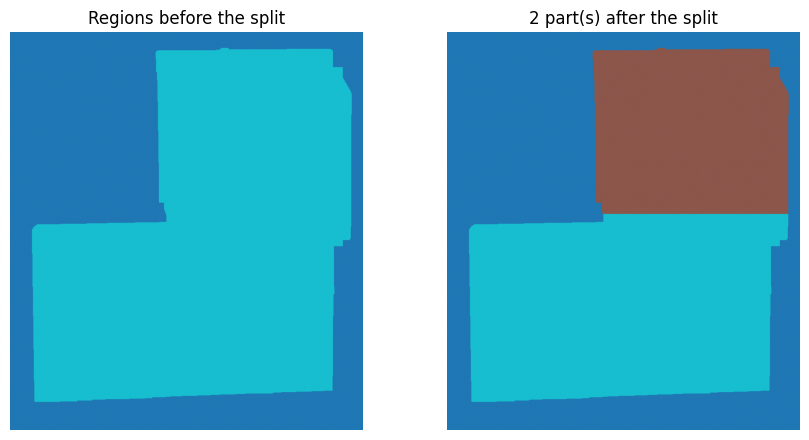

In [6]:
n, labels, stats, _ = cv2.connectedComponentsWithStats(steps["regions"], connectivity=8)
big = [l for l in range(1, n) if stats[l, cv2.CC_STAT_AREA] >= S.MIN_AREA_FRAC * steps["regions"].size]

for l in big:
    region = (labels == l).astype(np.uint8)
    ys, xs = np.nonzero(region)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    inside = steps["content"][y0:y1, x0:x1] * region[y0:y1, x0:x1]
    cut = S.find_cut(region, steps["content"])

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].imshow(inside, cmap="gray")
    axes[0].set_title(f"Region {l}: content inside its box")
    for ax, axis, name in ((axes[1], 0, "row"), (axes[2], 1, "column")):
        prof = inside.mean(axis=1 - axis)
        smooth = np.convolve(prof, np.ones(3) / 3, mode="same")
        k = len(prof)
        lo, hi = S.cut_range(k, inside.shape[1 - axis])
        i = lo + int(np.argmin(smooth[lo:hi]))
        ref = min(np.median(prof[:i]), np.median(prof[i:]))
        ax.plot(smooth, label="content fraction")
        ax.axhline(S.SPLIT_THR * ref, color="r", ls="--", label=f"cut threshold ({S.SPLIT_THR} x {ref:.2f})")
        ax.axvspan(0, lo, color="gray", alpha=0.2)
        ax.axvspan(hi, k, color="gray", alpha=0.2, label="no-cut margin")
        if cut is not None and cut[0] == axis:
            ax.axvline(cut[1] - (y0 if axis == 0 else x0), color="g", lw=3, label="cut")
            (axes[0].axhline if axis == 0 else axes[0].axvline)(cut[1] - (y0 if axis == 0 else x0), color="g", lw=3)
        ax.set_title(f"{name} profile")
        ax.set_xlabel(name)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    print(f"Region {l}: " + ("no cut (single painting)" if cut is None else f"cut at {'row' if cut[0] == 0 else 'column'} {cut[1]}"))

show([steps["regions"], sum((p * (i + 1) for i, p in enumerate(steps["parts"])), np.zeros((h, w), np.uint8))],
     ["Regions before the split", f"{len(steps['parts'])} part(s) after the split"], cmap="tab10")

## 6-7. Selection and rectangle (Weeks 3 and 2)

Each part is reduced to its largest blob with holes filled. It is kept if it covers at least
`MIN_AREA_FRAC` of the image, `MIN_REL_AREA` of the largest part and `MIN_EXTENT` of its bounding box
(a painting is rectangular). At most `MAX_PAINTINGS` (3) are kept. Then each one becomes the rectangle of the
rows and columns whose projection is above `PROJ_FRAC` × the maximum, which ignores small protrusions.

Part 1: area 22.3% of the image, extent 0.96
Part 2: area 38.5% of the image, extent 0.90
-> 2 painting(s) kept


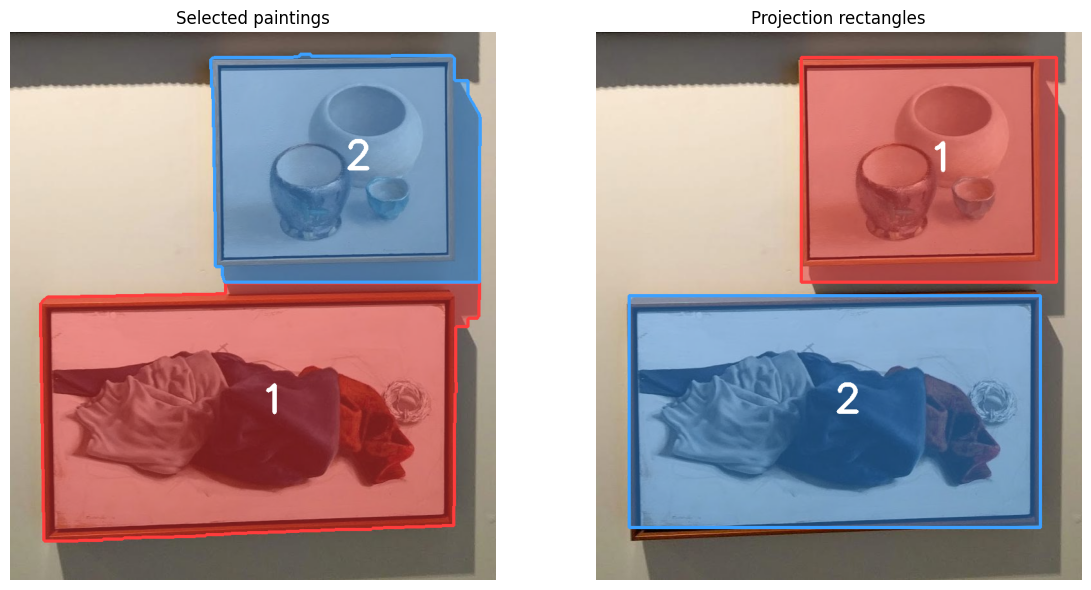

In [7]:
for i, part in enumerate(steps["parts"]):
    _, _, bw, bh = cv2.boundingRect(part)
    area = part.sum()
    print(f"Part {i + 1}: area {area / part.size:.1%} of the image, extent {area / (bw * bh):.2f}")
print(f"-> {len(steps['paintings'])} painting(s) kept" + ("  (none: fallback to the whole image)" if steps["fallback"] else ""))

if steps["paintings"]:
    show([overlay_masks(work, steps["paintings"]), overlay_masks(work, steps["rects"])],
         ["Selected paintings", "Projection rectangles"], size=6)

## 8. Result

Final masks at the original size (coloured) against the ground truth (green outline). The metrics are those
of the search: pixel precision, recall and F1 of the union of the masks, and whether the number of paintings
is right. The Week 3 detection is shown for comparison.

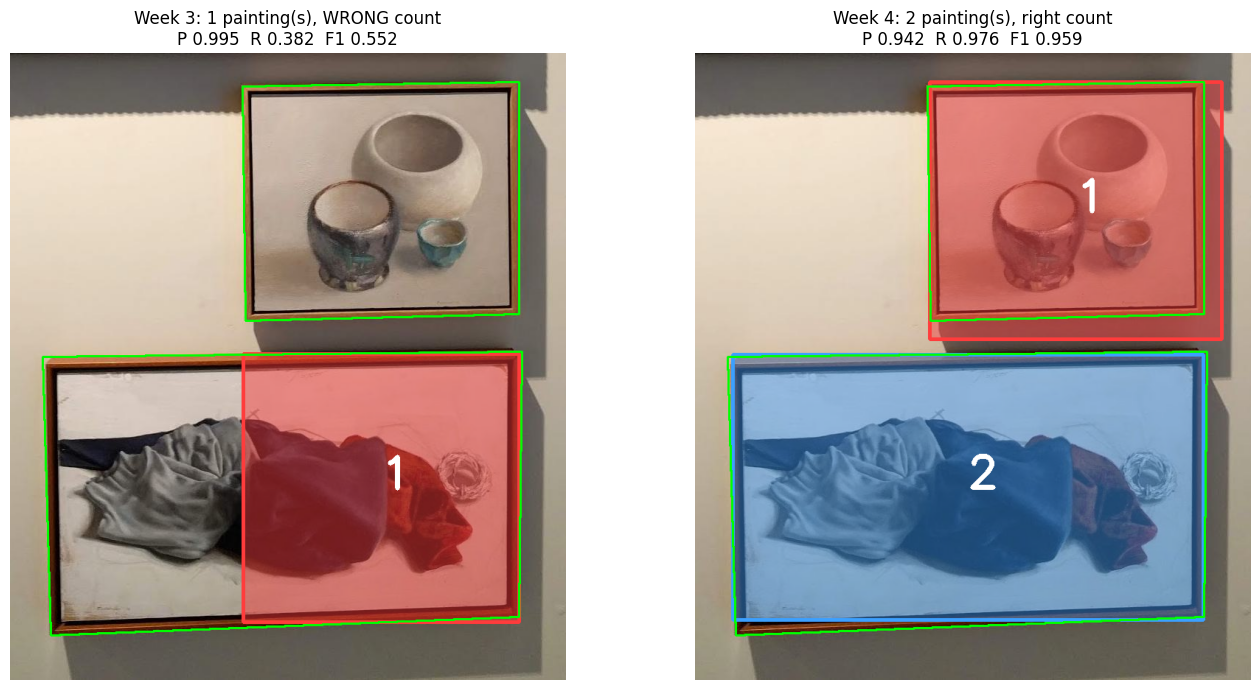

In [8]:
def result(masks, title):
    out = overlay_masks(den, masks)
    contours, _ = cv2.findContours(gt.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, contours, -1, (0, 255, 0), max(2, den.shape[1] // 300))
    p, r, f1 = scores(masks, gt)
    ok = "right" if len(masks) == n_gt else "WRONG"
    return out, f"{title}: {len(masks)} painting(s), {ok} count\nP {p:.3f}  R {r:.3f}  F1 {f1:.3f}"


w3 = detect_paintings_w3(den)
(a, ta), (b, tb) = result(w3, "Week 3"), result(steps["masks"], "Week 4")
show([a, b], [ta, tb], size=7)